<a href="https://colab.research.google.com/github/etoo-blip/Machine-Learning-Homework_5/blob/main/Homework5_Edwin_Too.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# HOMEWORK 5
# PROBLEM 1: NONLINEAR TEMPERATURE PREDICTION

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Temperature data from Lecture 8
t_c = [
    0.5, 14.0, 15.0, 28.0, 11.0, 8.0,
    3.0, -4.0, 6.0, 13.0, 21.0
]

t_u = [
    35.7, 55.9, 58.2, 81.9, 56.3, 48.9,
    33.9, 21.8, 48.4, 60.4, 68.4
]

# Convert lists to PyTorch tensors
t_c = torch.tensor(t_c, dtype=torch.float32)
t_u = torch.tensor(t_u, dtype=torch.float32)

# Normalize input measurements, as done in Lecture 8
t_un = 0.1 * t_u

print("Number of samples:", len(t_u))
print("\nNormalized input measurements:")
print(t_un)

Number of samples: 11

Normalized input measurements:
tensor([3.5700, 5.5900, 5.8200, 8.1900, 5.6300, 4.8900, 3.3900, 2.1800, 4.8400,
        6.0400, 6.8400])


In [2]:
# Nonlinear temperature model
def nonlinear_model(t_u, w2, w1, b):
    return w2 * t_u**2 + w1 * t_u + b

# Mean Squared Error loss function
def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()

# Initialize three trainable parameters
params = torch.tensor(
    [1.0, 1.0, 0.0],
    requires_grad=True
)

# Calculate initial predictions and loss
t_p = nonlinear_model(t_un, *params)
loss = loss_fn(t_p, t_c)

print("Initial parameters:", params)
print("Initial loss:", loss.item())

Initial parameters: tensor([1., 1., 0.], requires_grad=True)
Initial loss: 675.7943725585938


In [3]:
def training_loop(n_epochs, optimizer, params, t_u, t_c):

    loss_history = []

    for epoch in range(1, n_epochs + 1):

        # Forward pass
        t_p = nonlinear_model(t_u, *params)

        # Calculate loss
        loss = loss_fn(t_p, t_c)

        # Clear previous gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        # Store loss
        loss_history.append(loss.item())

        # Report every 500 epochs
        if epoch % 500 == 0:
            print(
                f"Epoch {epoch:4d} | "
                f"Loss: {loss.item():.6f}"
            )

        # Stop if training becomes numerically unstable
        if not torch.isfinite(loss):
            print("Training stopped: loss became non-finite.")
            break

    return params, loss_history

In [6]:
# Four learning rates required by the assignment
learning_rates = [0.1, 0.01, 0.001, 0.0001]

results = {}

for lr in learning_rates:

    print(f"\nTraining with learning rate = {lr}")
    print("-" * 45)

    # Fresh parameters for each training session
    params = torch.tensor(
    [0.0, 0.0, 0.0],
    requires_grad=True
)

    # SGD optimizer, as introduced in Lecture 8
    optimizer = torch.optim.SGD(
        [params],
        lr=lr
    )

    trained_params, losses = training_loop(
        n_epochs=5000,
        optimizer=optimizer,
        params=params,
        t_u=t_un,
        t_c=t_c
    )

    results[lr] = {
        "params": trained_params.detach().clone(),
        "losses": losses
    }

    print(f"Final loss: {losses[-1]:.6f}")


Training with learning rate = 0.1
---------------------------------------------
Epoch  500 | Loss: 2.090720
Epoch 1000 | Loss: 2.090720
Epoch 1500 | Loss: 2.090720
Epoch 2000 | Loss: 2.090720
Epoch 2500 | Loss: 2.090720
Epoch 3000 | Loss: 2.090720
Epoch 3500 | Loss: 2.090720
Epoch 4000 | Loss: 2.090720
Epoch 4500 | Loss: 2.090720
Epoch 5000 | Loss: 2.090720
Final loss: 2.090720

Training with learning rate = 0.01
---------------------------------------------
Epoch  500 | Loss: 2.091762
Epoch 1000 | Loss: 2.090720
Epoch 1500 | Loss: 2.090720
Epoch 2000 | Loss: 2.090720
Epoch 2500 | Loss: 2.090720
Epoch 3000 | Loss: 2.090720
Epoch 3500 | Loss: 2.090720
Epoch 4000 | Loss: 2.090720
Epoch 4500 | Loss: 2.090720
Epoch 5000 | Loss: 2.090720
Final loss: 2.090720

Training with learning rate = 0.001
---------------------------------------------
Epoch  500 | Loss: 25.546215
Epoch 1000 | Loss: 7.704172
Epoch 1500 | Loss: 3.731465
Epoch 2000 | Loss: 2.628516
Epoch 2500 | Loss: 2.276633
Epoch 3000 

In [7]:
# Standardize the temperature measurements
t_un = (t_u - t_u.mean()) / t_u.std(unbiased=False)

print("Standardized temperature inputs:")
print(t_un)

print("\nMean:", t_un.mean().item())
print("Standard deviation:", t_un.std(unbiased=False).item())


Standardized temperature inputs:
tensor([-1.0032,  0.2555,  0.3988,  1.8756,  0.2804, -0.1807, -1.1154, -1.8693,
        -0.2119,  0.5359,  1.0344])

Mean: -1.1920928955078125e-07
Standard deviation: 0.9999999403953552


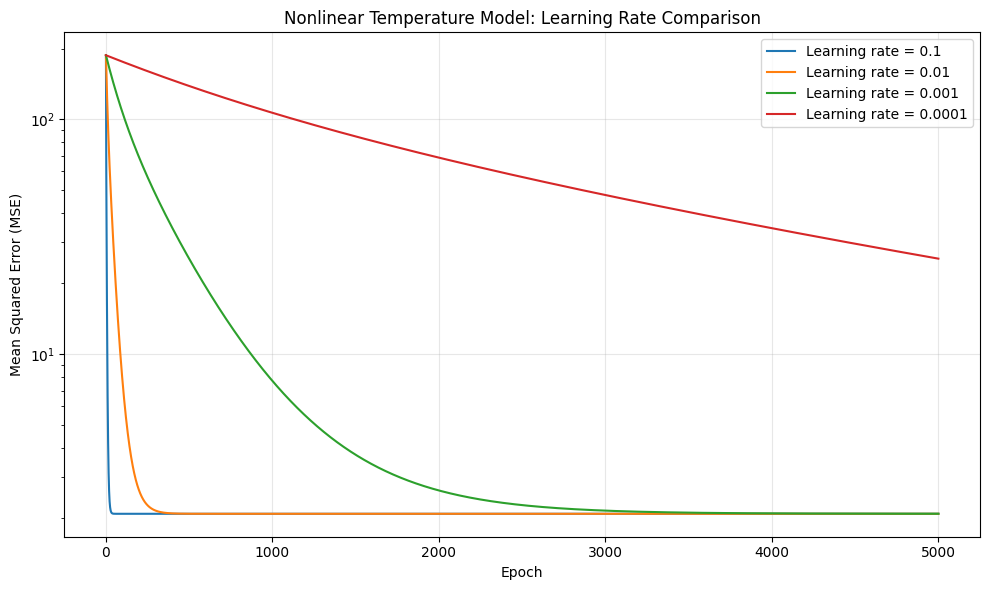

In [8]:
# Plot training loss for all four learning rates
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    plt.plot(
        range(1, len(results[lr]["losses"]) + 1),
        results[lr]["losses"],
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Nonlinear Temperature Model: Learning Rate Comparison")
plt.yscale("log")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Linear model final loss: 2.927645
Nonlinear model final loss: 2.090720

Best nonlinear parameters:
tensor([0.7290, 8.6797, 9.7710])


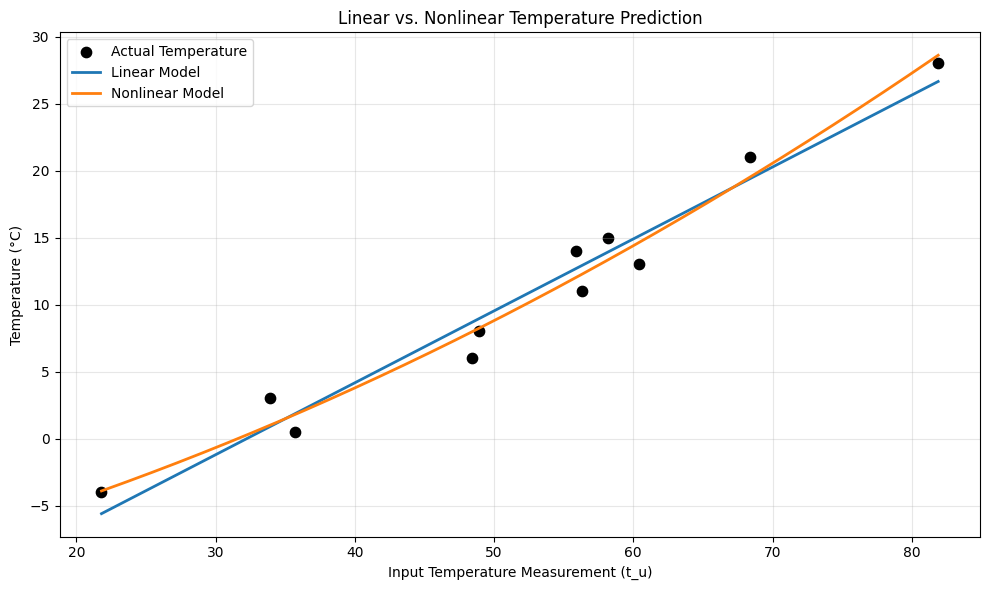

In [9]:
# PROBLEM 1(c): LINEAR VS NONLINEAR COMPARISON

# Best nonlinear model
best_lr = 0.1
best_params = results[best_lr]["params"]

# Train linear model using the same standardized inputs
def linear_model(t_u, w, b):
    return w * t_u + b

linear_params = torch.tensor(
    [0.0, 0.0],
    requires_grad=True
)

linear_optimizer = torch.optim.SGD(
    [linear_params],
    lr=0.1
)

for epoch in range(5000):
    t_p = linear_model(t_un, *linear_params)
    loss = loss_fn(t_p, t_c)

    linear_optimizer.zero_grad()
    loss.backward()
    linear_optimizer.step()

# Final losses
with torch.no_grad():
    linear_loss = loss_fn(
        linear_model(t_un, *linear_params), t_c
    ).item()

    nonlinear_loss = loss_fn(
        nonlinear_model(t_un, *best_params), t_c
    ).item()

print(f"Linear model final loss: {linear_loss:.6f}")
print(f"Nonlinear model final loss: {nonlinear_loss:.6f}")

print("\nBest nonlinear parameters:")
print(best_params)

# Generate smooth prediction curves
t_u_plot = torch.linspace(
    t_un.min(), t_un.max(), 200
)

with torch.no_grad():
    linear_predictions = linear_model(
        t_u_plot, *linear_params
    )

    nonlinear_predictions = nonlinear_model(
        t_u_plot, *best_params
    )

# Plot using original input measurements on the x-axis
t_u_original_plot = (
    t_u_plot * t_u.std(unbiased=False) + t_u.mean()
)

plt.figure(figsize=(10, 6))

plt.scatter(
    t_u.numpy(),
    t_c.numpy(),
    label="Actual Temperature",
    color="black",
    s=55
)

plt.plot(
    t_u_original_plot.numpy(),
    linear_predictions.numpy(),
    label="Linear Model",
    linewidth=2
)

plt.plot(
    t_u_original_plot.numpy(),
    nonlinear_predictions.numpy(),
    label="Nonlinear Model",
    linewidth=2
)

plt.xlabel("Input Temperature Measurement (t_u)")
plt.ylabel("Temperature (°C)")
plt.title("Linear vs. Nonlinear Temperature Prediction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# PROBLEM 2

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load housing dataset
housing = pd.read_csv("Housing.csv")

# Select five input variables
features_p2 = [
    "area",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking"
]

X_p2 = housing[features_p2]
Y_p2 = housing["price"]

print("Dataset shape:", housing.shape)
print("Number of features:", X_p2.shape[1])
print("\nFirst five records:")
print(X_p2.head())

Dataset shape: (545, 13)
Number of features: 5

First five records:
   area  bedrooms  bathrooms  stories  parking
0  7420         4          2        3        2
1  8960         4          4        4        3
2  9960         3          2        2        2
3  7500         4          2        2        3
4  7420         4          1        2        2


In [12]:
# Training and validation split
X_train_p2, X_val_p2, Y_train_p2, Y_val_p2 = train_test_split(
    X_p2,
    Y_p2,
    test_size=0.2,
    random_state=100
)

print("Training samples:", len(X_train_p2))
print("Validation samples:", len(X_val_p2))

Training samples: 436
Validation samples: 109


In [13]:
# Standardize input features
scaler_X_p2 = StandardScaler()

X_train_scaled_p2 = scaler_X_p2.fit_transform(X_train_p2)
X_val_scaled_p2 = scaler_X_p2.transform(X_val_p2)

# Standardize housing prices
scaler_Y_p2 = StandardScaler()

Y_train_scaled_p2 = scaler_Y_p2.fit_transform(
    Y_train_p2.to_numpy().reshape(-1, 1)
)

Y_val_scaled_p2 = scaler_Y_p2.transform(
    Y_val_p2.to_numpy().reshape(-1, 1)
)

# Convert to PyTorch tensors
X_train_tensor_p2 = torch.tensor(
    X_train_scaled_p2, dtype=torch.float32
)

X_val_tensor_p2 = torch.tensor(
    X_val_scaled_p2, dtype=torch.float32
)

Y_train_tensor_p2 = torch.tensor(
    Y_train_scaled_p2, dtype=torch.float32
)

Y_val_tensor_p2 = torch.tensor(
    Y_val_scaled_p2, dtype=torch.float32
)

print("Training input shape:", X_train_tensor_p2.shape)
print("Validation input shape:", X_val_tensor_p2.shape)
print("Training target shape:", Y_train_tensor_p2.shape)
print("Validation target shape:", Y_val_tensor_p2.shape)

Training input shape: torch.Size([436, 5])
Validation input shape: torch.Size([109, 5])
Training target shape: torch.Size([436, 1])
Validation target shape: torch.Size([109, 1])


In [14]:
print("Number of training samples:", X_train_tensor_p2.shape[0])
print("Number of validation samples:", X_val_tensor_p2.shape[0])
print("Number of input features:", X_train_tensor_p2.shape[1])

print("\nFeature means:")
print(np.round(X_train_scaled_p2.mean(axis=0), 4))

print("\nFeature standard deviations:")
print(np.round(X_train_scaled_p2.std(axis=0), 4))

print("\nTarget mean:",
      round(Y_train_scaled_p2.mean(), 4))

print("Target standard deviation:",
      round(Y_train_scaled_p2.std(), 4))

Number of training samples: 436
Number of validation samples: 109
Number of input features: 5

Feature means:
[ 0.  0. -0.  0. -0.]

Feature standard deviations:
[1. 1. 1. 1. 1.]

Target mean: 0.0
Target standard deviation: 1.0


In [15]:
# STEP 5: DEFINE THE LINEAR REGRESSION MODEL

import torch.nn as nn

# Linear regression model with 5 inputs and 1 output
model_p2 = nn.Linear(5, 1)

# Mean Squared Error loss function
loss_fn_p2 = nn.MSELoss()

print(model_p2)

print("\nNumber of trainable parameters:")
print(sum(p.numel() for p in model_p2.parameters()))

print("\nInitial weights:")
print(model_p2.weight.data)

print("\nInitial bias:")
print(model_p2.bias.data)

Linear(in_features=5, out_features=1, bias=True)

Number of trainable parameters:
6

Initial weights:
tensor([[ 0.2284, -0.0058, -0.2612, -0.1166, -0.3748]])

Initial bias:
tensor([0.4363])


In [16]:
# STEP 6: TRAINING LOOP

def train_housing_model(
    model,
    learning_rate,
    X_train,
    Y_train,
    X_val,
    Y_val,
    n_epochs=5000
):

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )

    history = []

    for epoch in range(1, n_epochs + 1):

        # Training
        model.train()

        predictions = model(X_train)
        train_loss = loss_fn_p2(predictions, Y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # Evaluate every 500 epochs
        if epoch % 500 == 0:

            model.eval()

            with torch.no_grad():

                train_predictions = model(X_train)
                val_predictions = model(X_val)

                train_loss_value = loss_fn_p2(
                    train_predictions, Y_train
                ).item()

                val_loss_value = loss_fn_p2(
                    val_predictions, Y_val
                ).item()

                # R2 calculated on standardized targets
                # R2 is unchanged by consistent linear scaling
                val_r2 = r2_score(
                    Y_val.numpy(),
                    val_predictions.numpy()
                )

            history.append({
                "Epoch": epoch,
                "Learning Rate": learning_rate,
                "Training Loss": train_loss_value,
                "Validation Loss": val_loss_value,
                "Validation R2": val_r2
            })

            print(
                f"Epoch {epoch:4d} | "
                f"Train Loss: {train_loss_value:.6f} | "
                f"Val Loss: {val_loss_value:.6f} | "
                f"Val R2: {val_r2:.4f}"
            )

    return model, pd.DataFrame(history)

In [17]:
# STEP 7: FOUR TRAINING SESSIONS

learning_rates_p2 = [0.1, 0.01, 0.001, 0.0001]

results_p2 = {}
histories_p2 = []

for lr in learning_rates_p2:

    print(f"\nTraining with learning rate = {lr}")
    print("-" * 65)

    # Reproducible initialization for each training
    torch.manual_seed(100)

    model = nn.Linear(5, 1)

    trained_model, history = train_housing_model(
        model=model,
        learning_rate=lr,
        X_train=X_train_tensor_p2,
        Y_train=Y_train_tensor_p2,
        X_val=X_val_tensor_p2,
        Y_val=Y_val_tensor_p2,
        n_epochs=5000
    )

    results_p2[lr] = {
        "model": trained_model,
        "history": history
    }

    histories_p2.append(history)

# Combine all results
all_history_p2 = pd.concat(
    histories_p2,
    ignore_index=True
)

print("\nTraining complete!")


Training with learning rate = 0.1
-----------------------------------------------------------------
Epoch  500 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 1000 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 1500 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 2000 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 2500 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 3000 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 3500 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 4000 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 4500 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477
Epoch 5000 | Train Loss: 0.437555 | Val Loss: 0.458961 | Val R2: 0.5477

Training with learning rate = 0.01
-----------------------------------------------------------------
Epoch  500 | Train Loss: 0.437556 | Val Loss: 0.458659 | Val R2: 0.5480
Epoch

In [18]:
# STEP 8: FINAL LEARNING RATE COMPARISON

final_comparison_p2 = (
    all_history_p2
    .groupby("Learning Rate")
    .tail(1)
    .sort_values("Validation R2", ascending=False)
)

print("Final Results After 5000 Epochs")
print(
    final_comparison_p2[
        [
            "Learning Rate",
            "Training Loss",
            "Validation Loss",
            "Validation R2"
        ]
    ].to_string(index=False)
)

Final Results After 5000 Epochs
 Learning Rate  Training Loss  Validation Loss  Validation R2
        0.0010       0.437556         0.458647       0.547967
        0.0100       0.437555         0.458961       0.547658
        0.1000       0.437555         0.458961       0.547657
        0.0001       0.572235         0.491320       0.515766


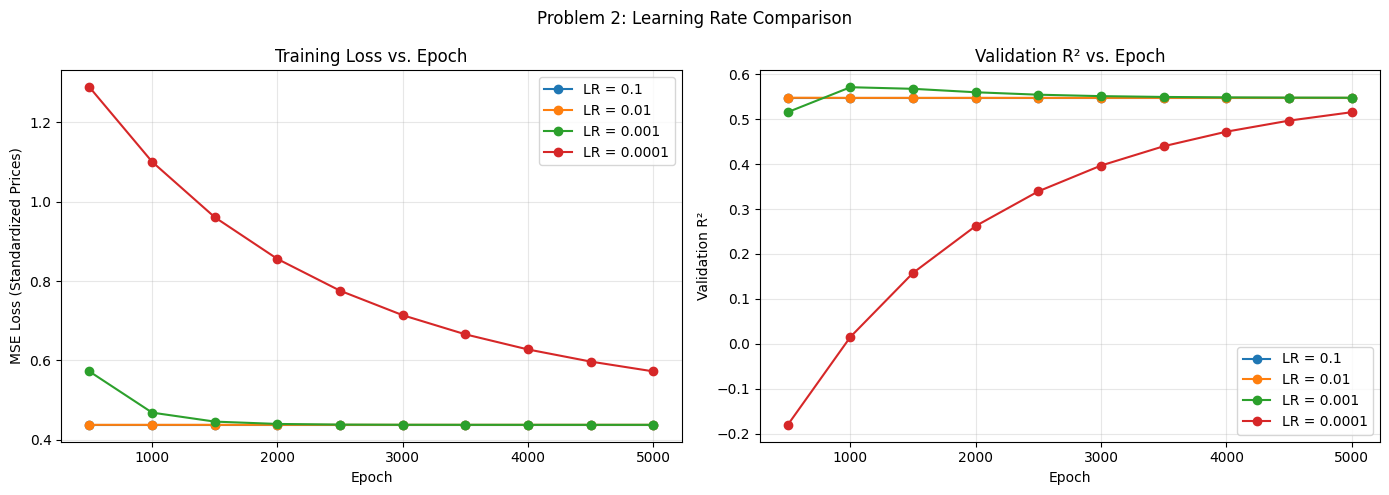

In [19]:
# STEP 10: TRAINING LOSS AND VALIDATION R2 PLOTS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr in learning_rates_p2:

    history = results_p2[lr]["history"]

    axes[0].plot(
        history["Epoch"],
        history["Training Loss"],
        marker="o",
        label=f"LR = {lr}"
    )

    axes[1].plot(
        history["Epoch"],
        history["Validation R2"],
        marker="o",
        label=f"LR = {lr}"
    )

axes[0].set_title("Training Loss vs. Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss (Standardized Prices)")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Validation R² vs. Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation R²")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.suptitle("Problem 2: Learning Rate Comparison")
plt.tight_layout()
plt.show()

In [20]:
# STEP 11: EXTRACT THE BEST MODEL PARAMETERS

best_lr_p2 = 0.001
best_model_p2 = results_p2[best_lr_p2]["model"]

# Extract standardized model parameters
weights_scaled = (
    best_model_p2.weight.detach().numpy().flatten()
)

bias_scaled = best_model_p2.bias.detach().numpy()[0]

print("Best Learning Rate:", best_lr_p2)

print("\nParameters in standardized units:")
for feature, weight in zip(features_p2, weights_scaled):
    print(f"{feature}: {weight:.6f}")

print(f"Bias: {bias_scaled:.6f}")

# Convert coefficients to original units
x_mean = scaler_X_p2.mean_
x_std = scaler_X_p2.scale_

y_mean = scaler_Y_p2.mean_[0]
y_std = scaler_Y_p2.scale_[0]

weights_original = weights_scaled * y_std / x_std

bias_original = (
    y_mean
    + y_std * bias_scaled
    - np.sum(weights_original * x_mean)
)

print("\nParameters in original housing-price units:")
for feature, weight in zip(features_p2, weights_original):
    print(f"{feature}: {weight:,.4f}")

print(f"Bias: {bias_original:,.4f}")

Best Learning Rate: 0.001

Parameters in standardized units:
area: 0.391031
bedrooms: 0.043711
bathrooms: 0.343270
stories: 0.248062
parking: 0.154310
Bias: 0.000010

Parameters in original housing-price units:
area: 339.4294
bedrooms: 111,864.5265
bathrooms: 1,274,588.4356
stories: 524,934.6398
parking: 334,066.5753
Bias: -124,935.9189


Best Model - Validation Performance
-----------------------------------
MAE:  934,136.88
RMSE: 1,263,108.25
R²:   0.5480


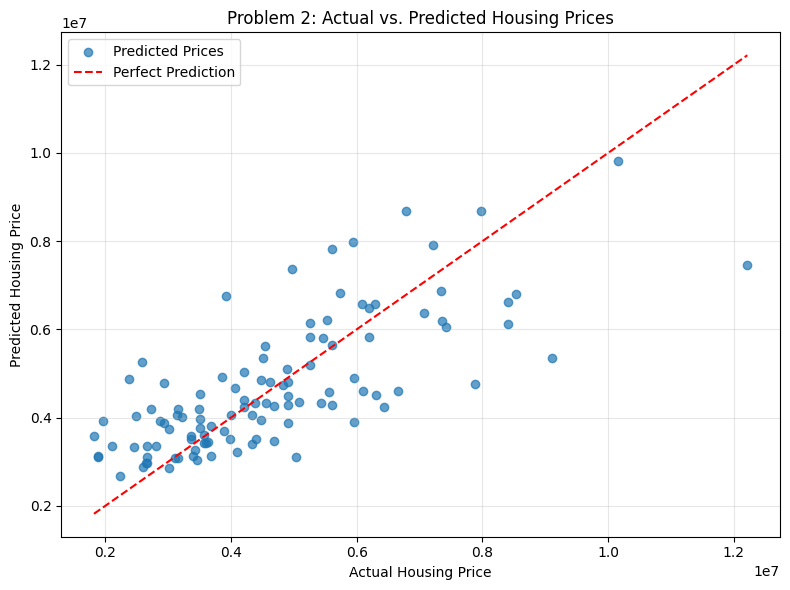

In [21]:
# STEP 12: ACTUAL VS. PREDICTED HOUSING PRICES

best_model_p2.eval()

with torch.no_grad():
    val_pred_scaled = (
        best_model_p2(X_val_tensor_p2).numpy()
    )

# Convert predictions back to original price units
val_pred_original = scaler_Y_p2.inverse_transform(
    val_pred_scaled
).flatten()

actual_prices = Y_val_p2.to_numpy()

# Calculate performance in original price units
mae_p2 = mean_absolute_error(
    actual_prices, val_pred_original
)

rmse_p2 = np.sqrt(
    mean_squared_error(actual_prices, val_pred_original)
)

r2_p2 = r2_score(
    actual_prices, val_pred_original
)

print("Best Model - Validation Performance")
print("-----------------------------------")
print(f"MAE:  {mae_p2:,.2f}")
print(f"RMSE: {rmse_p2:,.2f}")
print(f"R²:   {r2_p2:.4f}")

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_prices,
    val_pred_original,
    alpha=0.7,
    label="Predicted Prices"
)

min_price = min(actual_prices.min(), val_pred_original.min())
max_price = max(actual_prices.max(), val_pred_original.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Housing Price")
plt.ylabel("Predicted Housing Price")
plt.title("Problem 2: Actual vs. Predicted Housing Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:

#PROBLEM 3
# LINEAR REGRESSION USING ALL HOUSING FEATURES

# Separate input features and target
X_p3 = housing.drop(columns=["price"]).copy()
Y_p3 = housing["price"]

# Encode yes/no variables
binary_columns = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea"
]

for col in binary_columns:
    X_p3[col] = X_p3[col].map({"yes": 1, "no": 0})

# One-hot encode furnishing status
# Drop one category to avoid redundant dummy variables
X_p3 = pd.get_dummies(
    X_p3,
    columns=["furnishingstatus"],
    drop_first=True,
    dtype=int
)

print("Number of input features after encoding:", X_p3.shape[1])
print("\nFeature names:")
print(X_p3.columns.tolist())

print("\nMissing values:", X_p3.isnull().sum().sum())

Number of input features after encoding: 13

Feature names:
['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']

Missing values: 0


In [23]:
# Use the same split as Problem 2
X_train_p3, X_val_p3, Y_train_p3, Y_val_p3 = train_test_split(
    X_p3,
    Y_p3,
    test_size=0.2,
    random_state=100
)

# Standardize input features
scaler_X_p3 = StandardScaler()

X_train_scaled_p3 = scaler_X_p3.fit_transform(X_train_p3)
X_val_scaled_p3 = scaler_X_p3.transform(X_val_p3)

# Standardize target prices
scaler_Y_p3 = StandardScaler()

Y_train_scaled_p3 = scaler_Y_p3.fit_transform(
    Y_train_p3.to_numpy().reshape(-1, 1)
)

Y_val_scaled_p3 = scaler_Y_p3.transform(
    Y_val_p3.to_numpy().reshape(-1, 1)
)

# Convert to PyTorch tensors
X_train_tensor_p3 = torch.tensor(
    X_train_scaled_p3, dtype=torch.float32
)

X_val_tensor_p3 = torch.tensor(
    X_val_scaled_p3, dtype=torch.float32
)

Y_train_tensor_p3 = torch.tensor(
    Y_train_scaled_p3, dtype=torch.float32
)

Y_val_tensor_p3 = torch.tensor(
    Y_val_scaled_p3, dtype=torch.float32
)

print("Training input shape:", X_train_tensor_p3.shape)
print("Validation input shape:", X_val_tensor_p3.shape)
print("Training target shape:", Y_train_tensor_p3.shape)
print("Validation target shape:", Y_val_tensor_p3.shape)

Training input shape: torch.Size([436, 13])
Validation input shape: torch.Size([109, 13])
Training target shape: torch.Size([436, 1])
Validation target shape: torch.Size([109, 1])


In [24]:

# TRAIN USING ALL HOUSING FEATURES

learning_rates_p3 = [0.1, 0.01, 0.001, 0.0001]

results_p3 = {}
histories_p3 = []

for lr in learning_rates_p3:

    print(f"\nTraining with learning rate = {lr}")
    print("-" * 65)

    # Use identical initial parameters for each run
    torch.manual_seed(100)

    # 13 input features, 1 output
    model = nn.Linear(13, 1)

    trained_model, history = train_housing_model(
        model=model,
        learning_rate=lr,
        X_train=X_train_tensor_p3,
        Y_train=Y_train_tensor_p3,
        X_val=X_val_tensor_p3,
        Y_val=Y_val_tensor_p3,
        n_epochs=5000
    )

    results_p3[lr] = {
        "model": trained_model,
        "history": history
    }

    histories_p3.append(history)

# Combine results from all training sessions
all_history_p3 = pd.concat(
    histories_p3,
    ignore_index=True
)

print("\nAll four training sessions completed!")


Training with learning rate = 0.1
-----------------------------------------------------------------
Epoch  500 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 1000 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 1500 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 2000 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 2500 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 3000 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 3500 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 4000 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 4500 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807
Epoch 5000 | Train Loss: 0.321821 | Val Loss: 0.324019 | Val R2: 0.6807

Training with learning rate = 0.01
-----------------------------------------------------------------
Epoch  500 | Train Loss: 0.321832 | Val Loss: 0.324258 | Val R2: 0.6804
Epoch

In [25]:
# PROBLEM 3: FINAL LEARNING RATE COMPARISON

final_comparison_p3 = (
    all_history_p3
    .groupby("Learning Rate")
    .tail(1)
    .sort_values("Validation R2", ascending=False)
)

print("Problem 3: Final Results After 5000 Epochs")

print(
    final_comparison_p3[
        [
            "Learning Rate",
            "Training Loss",
            "Validation Loss",
            "Validation R2"
        ]
    ].to_string(index=False)
)

Problem 3: Final Results After 5000 Epochs
 Learning Rate  Training Loss  Validation Loss  Validation R2
        0.1000       0.321821         0.324019       0.680654
        0.0100       0.321821         0.324019       0.680654
        0.0010       0.321832         0.324260       0.680417
        0.0001       0.424892         0.416324       0.589680


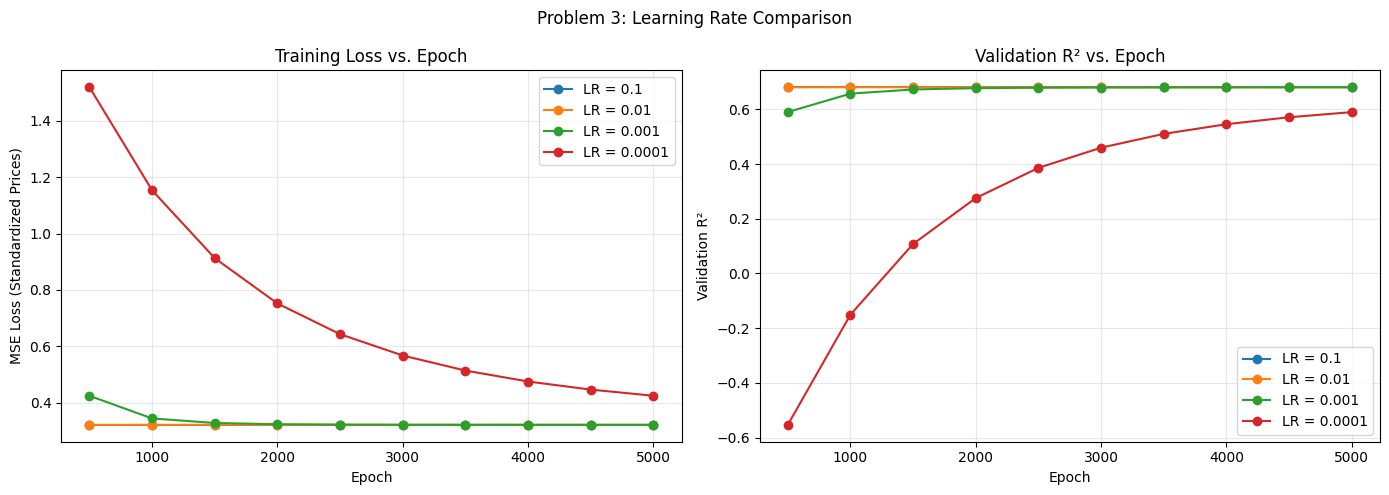

In [26]:
#LEARNING RATE COMPARISON PLOTS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr in learning_rates_p3:

    history = results_p3[lr]["history"]

    axes[0].plot(
        history["Epoch"],
        history["Training Loss"],
        marker="o",
        label=f"LR = {lr}"
    )

    axes[1].plot(
        history["Epoch"],
        history["Validation R2"],
        marker="o",
        label=f"LR = {lr}"
    )

axes[0].set_title("Training Loss vs. Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss (Standardized Prices)")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Validation R² vs. Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation R²")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.suptitle("Problem 3: Learning Rate Comparison")
plt.tight_layout()
plt.show()

In [27]:
#BEST MODEL PARAMETERS
best_lr_p3 = 0.1
best_model_p3 = results_p3[best_lr_p3]["model"]

# Extract standardized coefficients
weights_scaled_p3 = (
    best_model_p3.weight.detach().numpy().flatten()
)

bias_scaled_p3 = best_model_p3.bias.detach().numpy()[0]

print("Best Learning Rate:", best_lr_p3)

print("\nStandardized Parameters:")
for feature, weight in zip(X_p3.columns, weights_scaled_p3):
    print(f"{feature}: {weight:.6f}")

print(f"Bias: {bias_scaled_p3:.6f}")

# Convert coefficients to original price units
x_mean_p3 = scaler_X_p3.mean_
x_std_p3 = scaler_X_p3.scale_

y_mean_p3 = scaler_Y_p3.mean_[0]
y_std_p3 = scaler_Y_p3.scale_[0]

weights_original_p3 = (
    weights_scaled_p3 * y_std_p3 / x_std_p3
)

bias_original_p3 = (
    y_mean_p3
    + y_std_p3 * bias_scaled_p3
    - np.sum(weights_original_p3 * x_mean_p3)
)

print("\nParameters in Original Housing Price Units:")
for feature, weight in zip(X_p3.columns, weights_original_p3):
    print(f"{feature}: {weight:,.4f}")

print(f"Bias: {bias_original_p3:,.4f}")

Best Learning Rate: 0.1

Standardized Parameters:
area: 0.280473
bedrooms: 0.035449
bathrooms: 0.306334
stories: 0.191809
mainroad: 0.106229
guestroom: 0.077883
basement: 0.071176
hotwaterheating: 0.103678
airconditioning: 0.207728
parking: 0.111725
prefarea: 0.136732
furnishingstatus_semi-furnished: -0.026920
furnishingstatus_unfurnished: -0.107533
Bias: 0.000000

Parameters in Original Housing Price Units:
area: 243.4616
bedrooms: 90,722.7852
bathrooms: 1,137,441.5907
stories: 405,895.3058
mainroad: 575,124.5677
guestroom: 384,897.5881
basement: 277,737.5944
hotwaterheating: 847,855.5177
airconditioning: 845,077.8336
parking: 241,872.9249
prefarea: 604,469.6845
furnishingstatus_semi-furnished: -101,979.0101
furnishingstatus_unfurnished: -427,196.7489
Bias: -26,580.5031


Problem 3 - Best Model Validation Performance
----------------------------------------------
MAE:  785,292.31
RMSE: 1,061,661.91
R²:   0.6807


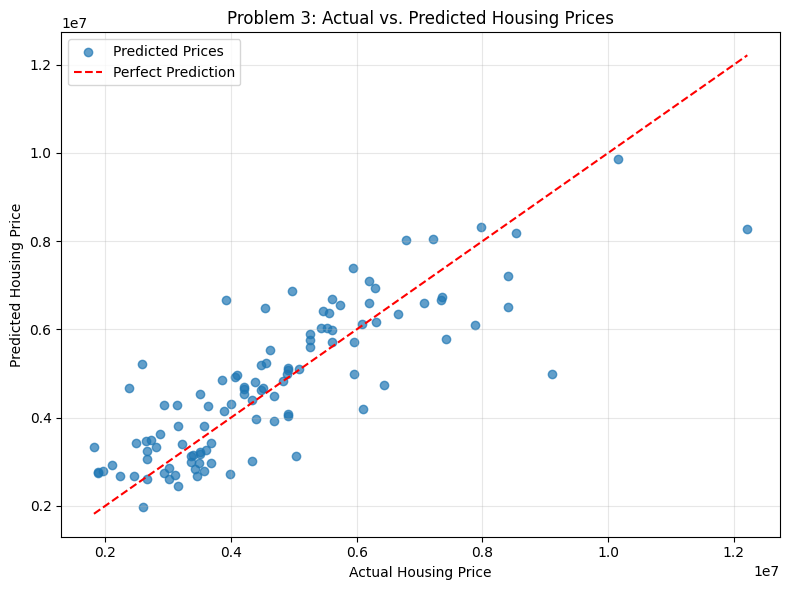

In [28]:
# ACTUAL VS. PREDICTED PRICES

best_model_p3.eval()

with torch.no_grad():
    val_pred_scaled_p3 = (
        best_model_p3(X_val_tensor_p3).numpy()
    )

# Convert predictions to original housing-price units
val_pred_original_p3 = scaler_Y_p3.inverse_transform(
    val_pred_scaled_p3
).flatten()

actual_prices_p3 = Y_val_p3.to_numpy()

# Calculate validation metrics
mae_p3 = mean_absolute_error(
    actual_prices_p3, val_pred_original_p3
)

rmse_p3 = np.sqrt(
    mean_squared_error(actual_prices_p3, val_pred_original_p3)
)

r2_p3 = r2_score(
    actual_prices_p3, val_pred_original_p3
)

print("Problem 3 - Best Model Validation Performance")
print("----------------------------------------------")
print(f"MAE:  {mae_p3:,.2f}")
print(f"RMSE: {rmse_p3:,.2f}")
print(f"R²:   {r2_p3:.4f}")

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_prices_p3,
    val_pred_original_p3,
    alpha=0.7,
    label="Predicted Prices"
)

min_price = min(
    actual_prices_p3.min(),
    val_pred_original_p3.min()
)

max_price = max(
    actual_prices_p3.max(),
    val_pred_original_p3.max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Housing Price")
plt.ylabel("Predicted Housing Price")
plt.title("Problem 3: Actual vs. Predicted Housing Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()